In [33]:
!pip install fredapi #allowing python to access to FRED data

from fredapi import Fred #importing Fred tool from fredapi
import pandas as pd #importing pandas so we can use it for short as 'pd'
import matplotlib.pyplot as plt
import numpy as np


fred = Fred(api_key= 'YOUR API KEY' ) #giving fred a variable name to be easier accessed and key so it could be used
cpi = fred.get_series("CPIAUCSL") # getting the cpi data from fred
print(cpi.head()) # .head() gives first 5 rows
print(cpi.tail()) # .tail() gives last 5 rows

1947-01-01    21.48
1947-02-01    21.62
1947-03-01    22.00
1947-04-01    22.00
1947-05-01    21.95
dtype: float64
2026-05-01    333.979
2026-06-01    332.568
2026-07-01    332.813
2026-08-01    334.131
2026-09-01    336.298
dtype: float64


In [34]:
print(type(cpi)) #checking to see if the type was right
print(len(cpi)) #telling you the length of the rows of cpi

<class 'pandas.core.series.Series'>
957


In [35]:
expected = fred.get_series('MICH') #getting the expected data from fred naming it expected
print(expected.head())
print(expected.tail())
print ('starts: ', expected.index.min()) #the starting date if the data
print ('ends: ', expected.index.max()) #ending date of the data
print ('rows: ', len(expected)) # number of rows of expected inflation data
print (type(expected)) #making sure the types of the two variables are the same

1978-01-01    5.2
1978-02-01    6.4
1978-03-01    6.3
1978-04-01    6.7
1978-05-01    6.9
dtype: float64
2026-05-01    4.8
2026-06-01    4.6
2026-07-01    4.2
2026-08-01    4.0
2026-09-01    4.6
dtype: float64
starts:  1978-01-01 00:00:00
ends:  2026-09-01 00:00:00
rows:  585
<class 'pandas.core.series.Series'>


In [36]:
print('CPI: ', cpi.index.min(), 'to', cpi.index.max()) #again comparing the length of the data because survey started later
print('Expected:', expected.index.min(), 'to', expected.index.max())


CPI:  1947-01-01 00:00:00 to 2026-09-01 00:00:00
Expected: 1978-01-01 00:00:00 to 2026-09-01 00:00:00


<Axes: title={'center': 'Expected Inflation% Progression'}, xlabel='Year', ylabel='Expected Inflation %'>

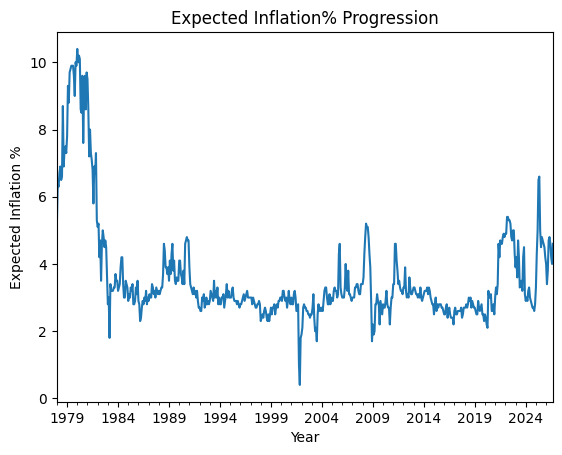

In [37]:
expected.plot(title= 'Expected Inflation% Progression', xlabel = 'Year', ylabel= 'Expected Inflation %')
#plotting the data for the expected list

In [38]:
cpi_year = cpi.pct_change(12)*100 #comparing the percent change in cpi with the values 12 rows before
df = pd.concat([cpi_year, expected], axis = 1, keys = ['cpi_year', 'expected'])
#making a spread sheet called df with the two variables side by side
df = df.dropna() #deletes the data rows that are missing so future calculations will not be affected
print (df)

            cpi_year  expected
1978-01-01  6.814310       5.2
1978-02-01  6.239460       6.4
1978-03-01  6.375839       6.3
1978-04-01  6.500000       6.7
1978-05-01  7.142857       6.9
...              ...       ...
2026-05-01  4.166615       4.8
2026-06-01  3.463531       4.6
2026-07-01  3.303856       4.2
2026-08-01  3.353016       4.0
2026-09-01  3.717251       4.6

[585 rows x 2 columns]


/tmp/ipykernel_1180/4134316515.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  cpi_year = cpi.pct_change(12)*100 #comparing the percent change in cpi with the values 12 rows before


<Axes: title={'center': 'Inflation Progression'}>

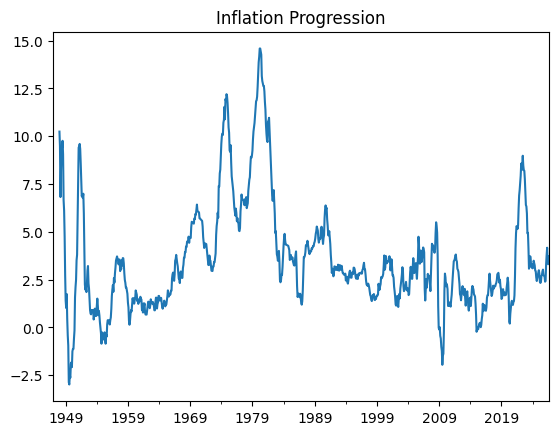

In [39]:
cpi_year.plot(title = 'Inflation Progression')

Text(0.5, 1.0, 'Expected vs actual inflation, 1978-2026')

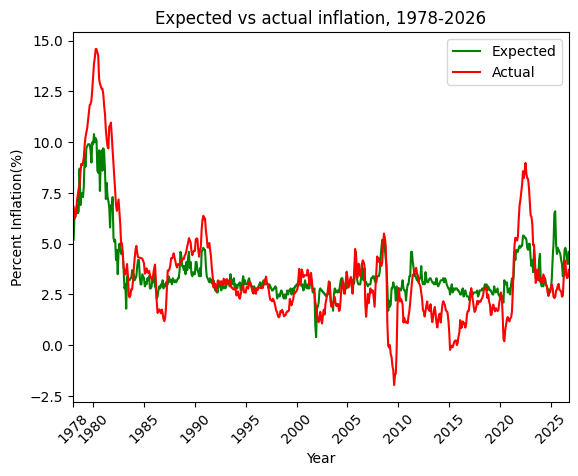

In [40]:
year = range (1,586,1) # starting at month 1 going up to month 585 since there is 585 months in the data set
plt.plot(year, df.iloc[:, 1], label = 'Expected', color = 'green')
plt.plot(year, df.iloc[:, 0], label = 'Actual', color = 'red')
plt.xlim(0,585)
plt.xticks((0,24,84,144,204,264,324,384,444,504,564), (1978, 1980,1985,1990,1995,2000,2005,2010,2015,2020,2025))
#making it so that the x axis ticks are in years that ends in 5 or 0 for visual, besides 1978 because that is the starting month
plt.xticks(rotation = 45) # so that the years wouldn't overlap
plt.legend(loc = 'upper right', fontsize = 10)
plt.xlabel('Year')
plt.ylabel('Percent Inflation(%)')
plt.title('Expected vs actual inflation, 1978-2026')

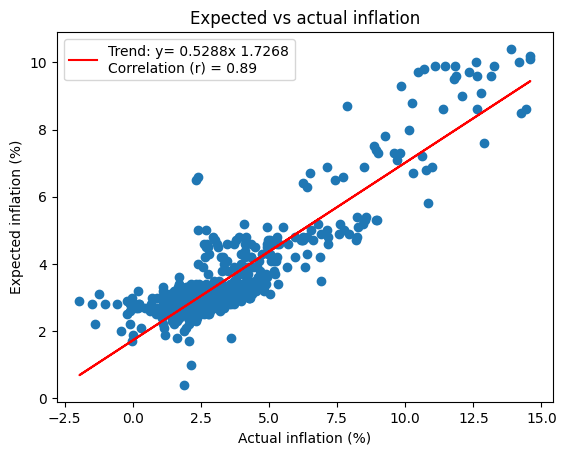

In [41]:
plt.scatter(df.iloc[:,0],df.iloc[:,1])
plt.xlabel("Actual inflation (%)")
plt.ylabel("Expected inflation (%)")
plt.title("Expected vs actual inflation")
x = df.iloc[:,0] # setting x to be the list of actual inflation
y = df.iloc[:,1] # setting y to be the list of expected inflation
m, b = np.polyfit(x, y, 1) #finding the line of best fit where y= b+mx, degree 1
r = np.corrcoef(x,y)[0,1] # finding correlation coefficient
plt.plot(x, m*x + b, color = 'red', label = f'Trend: y= {m:.4f}x {b:.4f}\nCorrelation (r) = {r:.2f}')
plt.legend(loc= 'upper left')

In [42]:
import sqlite3
conx = sqlite3.connect('inflation.db')
df.to_sql('monthly', conx, if_exists = 'replace', index_label='date') #importing to SQL as data table for later actions

585

In [43]:
ten_highest_expected = pd.read_sql("SELECT date, expected FROM monthly ORDER BY expected DESC LIMIT 10",conx)
average_of_two = pd.read_sql("SELECT AVG(expected - cpi_year) AS avg_gap FROM monthly",conx)
expect_more_2_actual = pd.read_sql("SELECT * FROM monthly WHERE (expected - cpi_year) >= 2",conx)
# could replace what in the " " with your own query

In [44]:
print(ten_highest_expected) # the 10 months with the highest expected inflation

                  date  expected
0  1980-01-01 00:00:00      10.4
1  1980-03-01 00:00:00      10.2
2  1980-04-01 00:00:00      10.1
3  1979-11-01 00:00:00      10.0
4  1980-02-01 00:00:00      10.0
5  1979-06-01 00:00:00       9.9
6  1979-07-01 00:00:00       9.9
7  1979-08-01 00:00:00       9.9
8  1979-12-01 00:00:00       9.9
9  1979-05-01 00:00:00       9.8


In [45]:
print(average_of_two) # the average of the inflation between the expected and actual

    avg_gap
0  0.043195


In [46]:
print(expect_more_2_actual) # the months where the expected inflation was higher by 2 points than actual

                   date  cpi_year  expected
0   2009-01-01 00:00:00 -0.113586       2.2
1   2009-03-01 00:00:00 -0.446479       2.0
2   2009-04-01 00:00:00 -0.576324       2.8
3   2009-05-01 00:00:00 -1.015761       2.8
4   2009-06-01 00:00:00 -1.229175       3.1
5   2009-07-01 00:00:00 -1.958761       2.9
6   2009-08-01 00:00:00 -1.483836       2.8
7   2009-09-01 00:00:00 -1.377943       2.2
8   2009-10-01 00:00:00 -0.223968       2.9
9   2013-09-01 00:00:00  1.094734       3.3
10  2013-10-01 00:00:00  0.876799       3.0
11  2014-02-01 00:00:00  1.120475       3.2
12  2014-12-01 00:00:00  0.653121       2.8
13  2015-01-01 00:00:00 -0.229931       2.5
14  2015-02-01 00:00:00 -0.087031       2.8
15  2015-03-01 00:00:00 -0.022031       3.0
16  2015-04-01 00:00:00 -0.104031       2.6
17  2015-05-01 00:00:00  0.035033       2.8
18  2015-06-01 00:00:00  0.179572       2.7
19  2015-07-01 00:00:00  0.225686       2.8
20  2015-08-01 00:00:00  0.241304       2.8
21  2015-09-01 00:00:00  0.00884